# 01 - Exploratory Data Analysis (Drug Reviews, Drugs.com)

**Lab Project on Recurrent Neural Networks - Advanced Natural Language Processing 2026/2027**

Goals of this notebook:
1. Check the raw files (separator, columns, missing values, duplicates, leakage between train and test).
2. Study the ratings and the 3-class target (**class imbalance**).
3. Study review lengths to choose a sensible `MAX_LEN`.
4. Look at the text (HTML entities, frequent words) and at the metadata.
5. Build and cache the prepared data (single fixed split) used by notebook 02.

> Run on Google Colab with a GPU runtime (the GPU is not needed here, but keep the same runtime as notebook 02).
Edit `DATA_DIR` in the first cell if your dataset is stored elsewhere on Drive.

In [2]:
# ============================ 0. Setup: Google Drive, paths ============================
import os, sys
from pathlib import Path

# >>> EDIT HERE: folder on Google Drive that contains drugsComTrain_raw.* and drugsComTest_raw.* <<<
DATA_DIR = "/content/drive/MyDrive/projet-lstm-drug-review/data"
# Project root on Google Drive (contains src/, notebooks/, results/)
PROJECT_ROOT = "/content/drive/MyDrive/projet-lstm-drug-review"

try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    # Not on Colab (local test): the project root is the parent of the notebooks/ folder.
    print("Not running on Colab: Google Drive is not mounted.")
    PROJECT_ROOT = str(Path.cwd().parent) if Path.cwd().name == "notebooks" else str(Path.cwd())

if not Path(PROJECT_ROOT, "src").is_dir():
    raise FileNotFoundError(
        f"Cannot find the src/ folder in PROJECT_ROOT = {PROJECT_ROOT}\n"
        "Check that you copied the whole project folder to Google Drive and that PROJECT_ROOT is correct.")
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)       # makes 'from src.cells import ...' work
os.chdir(PROJECT_ROOT)
print("Project root:", PROJECT_ROOT)
print("Data folder :", DATA_DIR)

Mounted at /content/drive
Project root: /content/drive/MyDrive/projet-lstm-drug-review
Data folder : /content/drive/MyDrive/projet-lstm-drug-review/data


In [4]:
# Auto-reload is optional. It fails on some Colab versions (Python 3.13: no module 'imp').
try:
    get_ipython().run_line_magic("load_ext", "autoreload")
    get_ipython().run_line_magic("autoreload", "2")
    print("Autoreload enabled.")
except Exception as error:
    print("Autoreload not available, continuing without it:", error)
    print("If you edit a file in src/, restart the runtime (Runtime > Restart session) to use the new code.")

Autoreload not available, continuing without it: No module named 'imp'
If you edit a file in src/, restart the runtime (Runtime > Restart session) to use the new code.


In [5]:
# ===================== Packages, GPU check and seeds =====================
import importlib.metadata as md, re, subprocess, random
import numpy as np

# Install only the packages of requirements.txt that are missing (Colab already has most of them).
missing = []
for line in Path(PROJECT_ROOT, "requirements.txt").read_text().splitlines():
    line = line.split("#")[0].strip()
    if not line:
        continue
    try:
        md.version(re.split(r"[<>=!~\[ ]", line)[0])
    except md.PackageNotFoundError:
        missing.append(line)
if missing:
    print("Installing missing packages:", missing)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
else:
    print("All packages from requirements.txt are already installed.")

SEED = 42
random.seed(SEED); np.random.seed(SEED)
try:
    import torch
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)
    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print("PyTorch", torch.__version__, "| device:", DEVICE,
          "|", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "NO GPU")
    if DEVICE.type == "cpu":
        print("WARNING: no GPU detected. In Colab: Runtime > Change runtime type > T4 GPU, then re-run.")
except ImportError:
    DEVICE = None
    print("PyTorch is not installed (only needed for notebook 02).")

All packages from requirements.txt are already installed.
PyTorch 2.11.0+cpu | device: cpu | NO GPU


## 1. Locate and load the raw files

In [6]:
import matplotlib.pyplot as plt
import pandas as pd
from collections import Counter
from IPython.display import display

from src import config
from src.data import (TRAIN_STEM, TEST_STEM, find_dataset_file, detect_separator, list_directory,
                      load_raw_dataframe, clean_text, tokenize, rating_to_label, class_names_from_bins,
                      class_counts, compute_class_weights, DataConfig, prepare_data)

FIG_DIR = config.FIGURES_DIR
FIG_DIR.mkdir(parents=True, exist_ok=True)

print("Files found in DATA_DIR:", list_directory(DATA_DIR))
train_path = find_dataset_file(DATA_DIR, TRAIN_STEM)   # raises a helpful error if the files are missing
test_path = find_dataset_file(DATA_DIR, TEST_STEM)
print("Train file:", train_path.name, "| separator:", repr(detect_separator(train_path)))
print("Test file :", test_path.name, "| separator:", repr(detect_separator(test_path)))

raw_train = pd.read_csv(train_path, sep=detect_separator(train_path))   # untouched, to count missing values
train_df = load_raw_dataframe(train_path)
test_df = load_raw_dataframe(test_path)
display(train_df.head(3))

Files found in DATA_DIR: ['drugsComTest_raw.csv', 'drugsComTrain_raw.csv']
Train file: drugsComTrain_raw.csv | separator: ','
Test file : drugsComTest_raw.csv | separator: ','


,uniqueID,drugName,condition,review,rating,date,usefulCount
0,206461,Valsartan,Left Ventricular Dysfunction,"""It has no side effect, I take it in combinati...",9,20-May-12,27
1,95260,Guanfacine,ADHD,"""My son is halfway through his fourth week of ...",8,27-Apr-10,192
2,92703,Lybrel,Birth Control,"""I used to take another oral contraceptive, wh...",5,14-Dec-09,17


In [7]:
print(f"Train file: {len(raw_train):,} rows | usable after dropping missing review/rating: {len(train_df):,}")
print(f"Test file : {len(test_df):,} usable rows")
print("\nMissing values per column in the raw train file:")
display(raw_train.isna().sum().to_frame("missing"))
numeric_cols = [c for c in ["rating", "usefulCount"] if c in train_df.columns]
display(train_df[numeric_cols].describe().round(2))

Train file: 161,297 rows | usable after dropping missing review/rating: 161,297
Test file : 53,766 usable rows

Missing values per column in the raw train file:


,missing
uniqueID,0
drugName,0
condition,899
review,0
rating,0
date,0
usefulCount,0


,rating,usefulCount
count,161297.00,161297.0
mean,6.99,28.0
std,3.27,36.4
min,1.00,0.0
25%,5.00,6.0
50%,8.00,16.0
75%,10.00,36.0
max,10.00,1291.0


In [8]:
# Duplicates and leakage between the official train and test files
if "uniqueID" in train_df.columns:
    print("Duplicated uniqueID in train:", int(train_df["uniqueID"].duplicated().sum()))
print("Duplicated review texts inside train:", int(train_df["review"].duplicated().sum()))
train_texts = set(train_df["review"])
overlap = int(test_df["review"].isin(train_texts).sum())
print(f"Test reviews whose exact text also appears in train: {overlap} ({overlap / len(test_df):.2%})")

Duplicated uniqueID in train: 0
Duplicated review texts inside train: 48968
Test reviews whose exact text also appears in train: 32216 (59.92%)


## 2. Ratings and the 3-class target

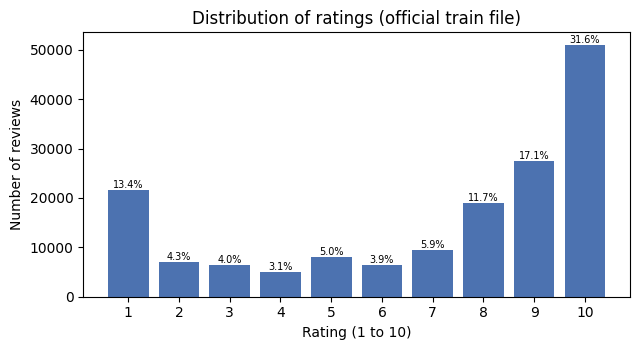

In [9]:
rating_counts = train_df["rating"].round().astype(int).value_counts().sort_index()
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.bar(rating_counts.index, rating_counts.values, color="#4C72B0")
ax.set_xlabel("Rating (1 to 10)")
ax.set_ylabel("Number of reviews")
ax.set_title("Distribution of ratings (official train file)")
ax.set_xticks(range(1, 11))
for x, y in zip(rating_counts.index, rating_counts.values):
    ax.text(x, y, f"{y / len(train_df):.1%}", ha="center", va="bottom", fontsize=7)
plt.tight_layout(); plt.savefig(FIG_DIR / "eda_rating_distribution.png", dpi=130); plt.show()

Mapping: [('1-4', 'negative'), ('5-6', 'neutral'), ('7-10', 'positive')]


,train_count,test_count,train_share,test_share
negative,40075,13497,0.2485,0.2510
neutral,14356,4829,0.0890,0.0898
positive,106866,35440,0.6625,0.6592


Imbalance ratio (largest class / smallest class) in train: 7.4
Majority-class baseline accuracy on test: 0.6592
'Balanced' class weights (N / (K * n_c)): {'negative': 1.342, 'neutral': 3.745, 'positive': 0.503}


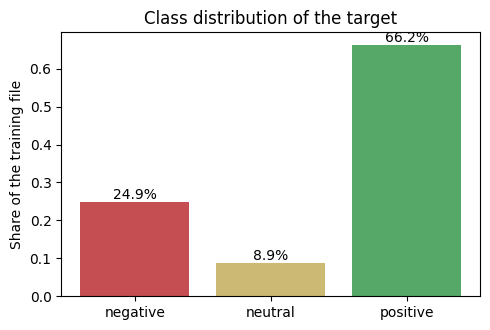

In [10]:
# Mapping rating -> class is defined in src/config.py (LABEL_BINS) and is configurable.
BINS = config.LABEL_BINS
names = class_names_from_bins(BINS)
print("Mapping:", [(f"{lo}-{hi}", n) for lo, hi, n in BINS])

train_labels = rating_to_label(train_df["rating"].to_numpy(), BINS)
test_labels = rating_to_label(test_df["rating"].to_numpy(), BINS)
summary = pd.DataFrame({
    "train_count": class_counts(train_labels, len(names)),
    "test_count": class_counts(test_labels, len(names)),
}, index=names)
summary["train_share"] = (summary["train_count"] / summary["train_count"].sum()).round(4)
summary["test_share"] = (summary["test_count"] / summary["test_count"].sum()).round(4)
display(summary)

ratio = summary["train_count"].max() / summary["train_count"].min()
print(f"Imbalance ratio (largest class / smallest class) in train: {ratio:.1f}")
print("Majority-class baseline accuracy on test:", round(summary["test_share"].max(), 4))
print("'Balanced' class weights (N / (K * n_c)):",
      {n: round(float(w), 3) for n, w in zip(names, compute_class_weights(train_labels, len(names)))})

fig, ax = plt.subplots(figsize=(5, 3.4))
ax.bar(names, summary["train_share"], color=["#C44E52", "#CCB974", "#55A868"][: len(names)])
ax.set_ylabel("Share of the training file")
ax.set_title("Class distribution of the target")
for i, v in enumerate(summary["train_share"]):
    ax.text(i, v, f"{v:.1%}", ha="center", va="bottom")
plt.tight_layout(); plt.savefig(FIG_DIR / "eda_class_distribution.png", dpi=130); plt.show()

**Why this matters:** with a strongly imbalanced target, accuracy alone is misleading (a model that always predicts the
majority class already scores the "majority-class baseline accuracy" printed above). We therefore report **macro-F1** (mean of
the per-class F1, every class counts equally) and we compare training with and without **class weights**.

## 3. Review length (to choose MAX_LEN)

Words per review (whitespace split, whole train file):


,words
count,161297.0
mean,84.7
std,45.0
min,1.0
50%,84.0
75%,126.0
90%,141.0
95%,146.0
99%,154.0
max,1894.0


MAX_LEN = 100:  40.1% of the reviews are truncated
MAX_LEN = 150:   3.5% of the reviews are truncated
MAX_LEN = 200:   0.2% of the reviews are truncated
MAX_LEN = 300:   0.1% of the reviews are truncated
MAX_LEN = 400:   0.1% of the reviews are truncated


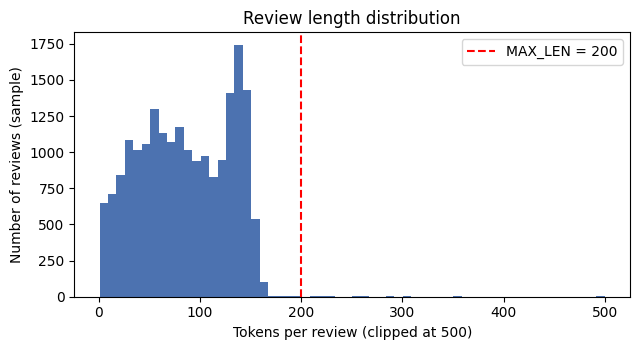

,count,mean,std,min,25%,50%,75%,max
class,,,,,,,,
negative,4963.0,82.4,46.6,1.0,46.0,79.0,124.0,893.0
neutral,1728.0,86.6,43.7,1.0,51.0,85.0,127.0,257.0
positive,13309.0,86.3,47.0,1.0,48.0,86.0,129.0,1099.0


In [11]:
import numpy as np
words = train_df["review"].str.split().str.len()
print("Words per review (whitespace split, whole train file):")
display(words.describe(percentiles=[.5, .75, .9, .95, .99]).round(1).to_frame("words"))

# Exact token counts on a random sample (tokenizing the whole file takes longer)
rng = np.random.default_rng(0)
sample_idx = rng.choice(len(train_df), size=min(20000, len(train_df)), replace=False)
sample_tokens = [tokenize(train_df["review"].iloc[i]) for i in sample_idx]
sample_len = np.array([len(t) for t in sample_tokens])
sample_labels = train_labels[sample_idx]
for max_len in (100, 150, 200, 300, 400):
    print(f"MAX_LEN = {max_len:>3}: {np.mean(sample_len > max_len):6.1%} of the reviews are truncated")

fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.hist(np.clip(sample_len, 0, 500), bins=60, color="#4C72B0")
ax.axvline(config.MAX_LEN, color="red", linestyle="--", label=f"MAX_LEN = {config.MAX_LEN}")
ax.set_xlabel("Tokens per review (clipped at 500)")
ax.set_ylabel("Number of reviews (sample)")
ax.set_title("Review length distribution")
ax.legend()
plt.tight_layout(); plt.savefig(FIG_DIR / "eda_length_distribution.png", dpi=130); plt.show()

by_class = pd.DataFrame({"length": sample_len, "class": [names[k] for k in sample_labels]})
display(by_class.groupby("class")["length"].describe().round(1).loc[names])

## 4. Text content and cleaning

In [12]:
has_entity = train_df["review"].str.contains(r"&#?\w+;", regex=True)
print(f"Reviews containing HTML entities before cleaning: {has_entity.mean():.1%}")
example = train_df.loc[has_entity, "review"].iloc[0]
print("\nBEFORE:", example[:300])
print("AFTER :", clean_text(example)[:300])
print("TOKENS:", tokenize(example)[:25])

Reviews containing HTML entities before cleaning: 65.3%

BEFORE: "I used to take another oral contraceptive, which had 21 pill cycle, and was very happy- very light periods, max 5 days, no other side effects. But it contained hormone gestodene, which is not available in US, so I switched to Lybrel, because the ingredients are similar. When my other pills ended, I
AFTER : "i used to take another oral contraceptive, which had 21 pill cycle, and was very happy- very light periods, max 5 days, no other side effects. but it contained hormone gestodene, which is not available in us, so i switched to lybrel, because the ingredients are similar. when my other pills ended, i
TOKENS: ['i', 'used', 'to', 'take', 'another', 'oral', 'contraceptive', 'which', 'had', '21', 'pill', 'cycle', 'and', 'was', 'very', 'happy', 'very', 'light', 'periods', 'max', '5', 'days', 'no', 'other', 'side']


In [13]:
STOP = set("the a an and or but of to in on for with at by from is was are were be been it its this that these those "
           "i me my we you he she they them his her our their as so if then than too very just not no have has had "
           "do did does can could would should will am im ive i've i'm it's don't didn't".split())
top = {}
for k, name in enumerate(names):
    counter = Counter()
    for tokens, label in zip(sample_tokens, sample_labels):
        if label == k:
            counter.update(t for t in tokens if t not in STOP and len(t) > 1)
    top[name] = [w for w, _ in counter.most_common(15)]
print("Most frequent words per class (stop words removed, 20k-review sample):")
display(pd.DataFrame(top))

Most frequent words per class (stop words removed, 20k-review sample):


,negative,neutral,positive
0,after,about,after
1,all,after,about
2,taking,day,day
3,day,now,side
4,out,side,now
5,months,taking,years
6,now,first,taking
7,started,months,mg
8,pain,all,take
9,like,mg,effects


## 5. Metadata (conditions, drugs, dates, usefulness)

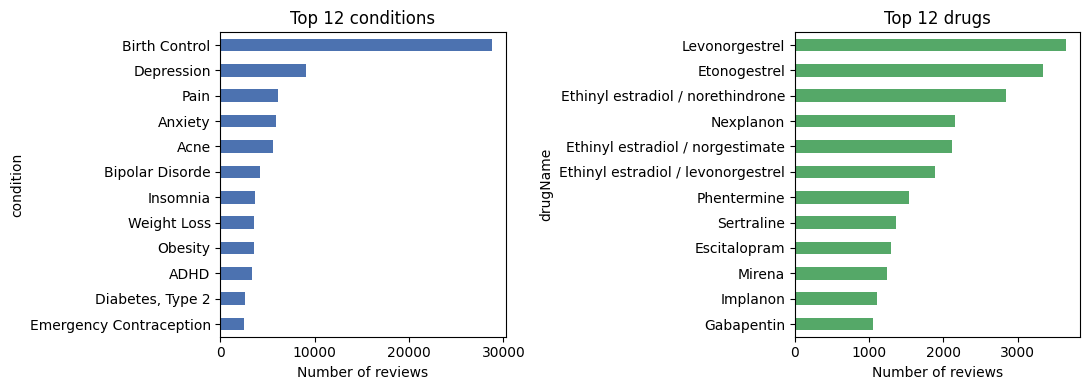

Distinct conditions: 884 | distinct drugs: 3436


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
if "condition" in train_df.columns:
    train_df["condition"].value_counts().head(12).iloc[::-1].plot.barh(ax=axes[0], color="#4C72B0")
    axes[0].set_title("Top 12 conditions")
    axes[0].set_xlabel("Number of reviews")
if "drugName" in train_df.columns:
    train_df["drugName"].value_counts().head(12).iloc[::-1].plot.barh(ax=axes[1], color="#55A868")
    axes[1].set_title("Top 12 drugs")
    axes[1].set_xlabel("Number of reviews")
plt.tight_layout(); plt.savefig(FIG_DIR / "eda_conditions_drugs.png", dpi=130); plt.show()
if "condition" in train_df.columns:
    print("Distinct conditions:", train_df["condition"].nunique(), "| distinct drugs:", train_df["drugName"].nunique())

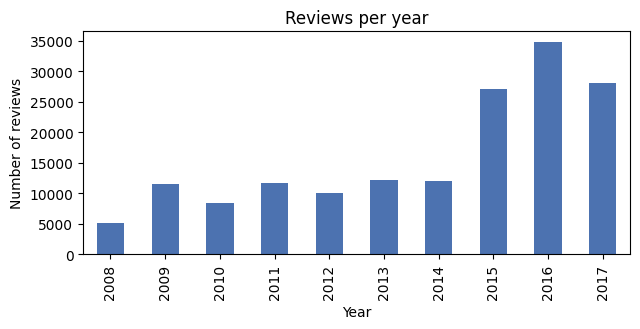

usefulCount: median = 16.0 | 99th percentile = 166.0


In [15]:
if "date" in train_df.columns:
    years = pd.to_datetime(train_df["date"], format="%d-%b-%y", errors="coerce").dt.year.dropna().astype(int)
    fig, ax = plt.subplots(figsize=(6.5, 3.4))
    years.value_counts().sort_index().plot.bar(ax=ax, color="#4C72B0")
    ax.set_title("Reviews per year")
    ax.set_xlabel("Year")
    ax.set_ylabel("Number of reviews")
    plt.tight_layout(); plt.savefig(FIG_DIR / "eda_reviews_per_year.png", dpi=130); plt.show()
if "usefulCount" in train_df.columns:
    print("usefulCount: median =", train_df["usefulCount"].median(), "| 99th percentile =",
          train_df["usefulCount"].quantile(0.99))

## 6. Prepared data used by the models (single fixed split)

* test = official test file; train/validation = official train file split once (stratified, fixed seed);
* vocabulary built on the **training split only**; `<PAD>` = 0, `<UNK>` = 1; head truncation at `MAX_LEN`.
* The result is cached in `cache/` on Drive: the next notebook reloads it in a few seconds.

In [16]:
DATA_CFG = DataConfig()    # defaults come from src/config.py (MAX_LEN, MIN_FREQ, MAX_VOCAB, VAL_SIZE, SPLIT_SEED, LABEL_BINS)
print(DATA_CFG)
data = prepare_data(DATA_DIR, DATA_CFG, cache_dir=config.CACHE_DIR)

DataConfig(max_len=200, min_freq=3, max_vocab=30000, val_size=0.1, split_seed=42, label_bins=((1, 4, 'negative'), (5, 6, 'neutral'), (7, 10, 'positive')))
[data] Loaded prepared data from cache: /content/drive/MyDrive/projet-lstm-drug-review/cache/prepared_00521724e49c.npz


Split sizes: {'train': 145166, 'val': 16131, 'test': 53766}


count                 share                
          train    val   test   train     val    test
negative  36067   4008  13497  0.2485  0.2485  0.2510
neutral   12920   1436   4829  0.0890  0.0890  0.0898
positive  96179  10687  35440  0.6625  0.6625  0.6592

train: <UNK> rate = 0.26% | reviews hitting MAX_LEN = 0.2%
  val: <UNK> rate = 0.33% | reviews hitting MAX_LEN = 0.2%
 test: <UNK> rate = 0.34% | reviews hitting MAX_LEN = 0.1%
Vocabulary size: 23611 | first tokens: ['<PAD>', '<UNK>', 'i', 'and', 'the', 'to', 'my', 'a', 'it', 'for', 'was', 'have']


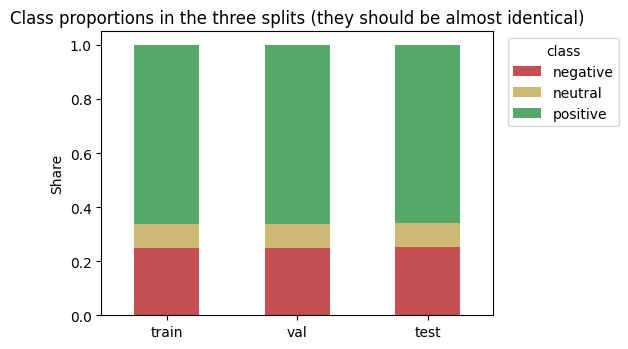

In [17]:
sizes = data.info["sizes"]
table = pd.DataFrame({s: data.info["class_counts"][s] for s in ("train", "val", "test")}, index=data.class_names)
shares = (table / table.sum()).round(4)
print("Split sizes:", sizes)
display(pd.concat({"count": table, "share": shares}, axis=1))

# Out-of-vocabulary rate: share of real tokens mapped to <UNK> (id 1)
for split_name in ("train", "val", "test"):
    s = data.splits[split_name]
    real = np.arange(s.ids.shape[1])[None, :] < s.lengths[:, None]
    print(f"{split_name:>5}: <UNK> rate = {np.mean(s.ids[real] == 1):.2%} | "
          f"reviews hitting MAX_LEN = {np.mean(s.lengths == data.cfg.max_len):.1%}")
print("Vocabulary size:", len(data.vocab), "| first tokens:", data.vocab.itos[:12])

shares.T.plot.bar(stacked=True, figsize=(6, 3.6), color=["#C44E52", "#CCB974", "#55A868"][: len(names)])
plt.title("Class proportions in the three splits (they should be almost identical)")
plt.ylabel("Share"); plt.xticks(rotation=0); plt.legend(title="class", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout(); plt.savefig(FIG_DIR / "eda_split_class_proportions.png", dpi=130); plt.show()

## 7. Notes for the report
* **Sizes and classes.** 161,297 training and 53,766 test reviews, 3 classes: negative 24.9%, neutral 8.9%, positive 66.3% in train (25.1% / 9.0% / 65.9% in test). Imbalance ratio 7.4; the majority-class baseline gives 0.659 accuracy on the test set, so we report macro-F1 and compare class weights. Splits used by all models: 145,166 train / 16,131 validation (stratified, seed 42) / 53,766 test; the class proportions are almost identical in the three splits.
* **Length.** Median 84 words, 99th percentile 154; MAX_LEN = 200 truncates only 0.2% of the reviews (MAX_LEN = 100 would truncate 40.1%).
* **Cleaning.** 65.3% of the reviews contain HTML entities (decoded with html.unescape); lowercase, word tokenization. Vocabulary of 23,611 tokens (min_freq = 3) built on the training split only; <UNK> rate 0.26% (train), 0.33% (validation), 0.34% (test).
* **Data quality.** 899 missing conditions; 48,968 duplicated review texts in the training file, and 59.92% of the test reviews (32,216) also appear in the training file (possible leakage, stated as a limitation).
* **Metadata.** 884 distinct conditions and 3,436 distinct drugs; usefulCount is very skewed (median 16, 99th percentile 166). These columns are not used by the models.
* **Consequences.** Stratified split and sub-sampling, macro-F1 as main metric, class weights as an option.